# Week 2: Context, Sampling and In-Context Learning

## Overview
Last week we looked at the edges of a model: what goes in (tokenisation) and what comes out (a next-token distribution). This week we work on the part in the middle that engineers touch every day: what we put in the context window, and how we turn the resulting distribution into text. The anchor reading is *Language Models are Few-Shot Learners* (Brown et al., 2020).

The paper's headline claim is that a model can pick up a task from a handful of examples placed in its prompt, with no weight updates, and that this gets better with more examples and with scale. We will test a small version of that claim ourselves, on two small models, and we will be careful about how much we trust each number.

## Concepts covered
- **In-context learning**: the model conditions on demonstrations written into the prompt and continues the pattern. Nothing is trained. Whatever is "learned" lives only for the length of that context.
- **Few-shot design**: the count, order and format of the demonstrations are all choices, and each one can change the output. Part of this week is finding out how much.
- **Context window limits**: every model has a maximum number of positions. Past it, you either get an error, a silent truncation, or something worse. We will check this deliberately, not by accident.
- **Sampling**: temperature, top-k and top-p are transformations applied to the logits before a token is drawn. We will implement them from scratch and look at what each one does to the distribution we studied last week.

#### Further into Sampling
1. Temperature: A scaling factor applied to raw logits to adjust output randomness, where lower values increase focus and predictability, while higher values increase creative variety.
2. Top-$k$: A filtering technique that restricts token selection to a fixed count ($k$) of the highest-probability candidate tokens.
3. Top-$p$: A filtering technique that restricts token selection to a dynamic pool of highest-probability tokens whose cumulative probability reaches a target threshold ($p$).

## Task
Systematically vary few-shot examples (count, order, format) on a fixed task and document what actually moves output quality.

In [ ]:
# Install dependencies
!pip install -q transformers accelerate torch pandas matplotlib

### Loading the models
We keep the same two models as week 1 so you can compare directly with what you saw then: GPT-2 (2019, 124M parameters) and Qwen2.5-0.5B (2024, 0.5B parameters). Both are base models, not instruction-tuned, which matters here: they continue text rather than follow instructions, so the prompt format is doing real work.

In [ ]:
import os
import random
import torch
import torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM

try:
    from google.colab import userdata
    os.environ["HF_TOKEN"] = userdata.get("Flow_HF_Token")
except Exception:
    pass  # not on Colab, or no secret set; public models still load

MODEL_IDS = {
    "gpt2": "gpt2",
    "qwen": "Qwen/Qwen2.5-0.5B",
}

device = "cuda" if torch.cuda.is_available() else "cpu"

tokenizers = {name: AutoTokenizer.from_pretrained(mid) for name, mid in MODEL_IDS.items()}
models = {
    name: AutoModelForCausalLM.from_pretrained(mid, dtype=torch.float32).to(device).eval()
    for name, mid in MODEL_IDS.items()
}

print(f"Loaded {list(MODEL_IDS.values())} on {device}")

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

Loaded ['gpt2', 'Qwen/Qwen2.5-0.5B'] on cuda


## Part 1: The fixed task
We need a task with a known answer key so that "quality" means something measurable. We use binary sentiment classification over short, hand-written reviews. The pool of demonstrations and the held-out test set are kept separate, so no demonstration can leak into the test.

Two design choices worth understanding before you run anything:
- **We score by label log-probability, not by generating text.** For each test review we run one forward pass and compare the model's log-probability for ` positive` against ` negative` at the next-token position. This is deterministic, so any change in accuracy comes from the prompt, not from sampling luck.
- **We track more than accuracy.** Accuracy near 50% can mean "knows nothing" or "always answers the same label". We also record how often the model predicts positive, and how much probability mass lands on the two valid labels at all.

In [ ]:
LABELS = ["positive", "negative"]

# Demonstration pool: 8 positive, 8 negative
POOL = [
    ("The battery lasts all week and the screen is gorgeous.", "positive"),
    ("The app crashes every time I try to upload a photo.", "negative"),
    ("Staff were warm, the room was spotless, and we slept like babies.", "positive"),
    ("Waited forty minutes for cold food and nobody apologised.", "negative"),
    ("I expected a slog but finished the book in two sittings.", "positive"),
    ("The plot made no sense and the ending felt like an insult.", "negative"),
    ("Setup took five minutes and everything just worked.", "positive"),
    ("It broke after two days and the refund process was a nightmare.", "negative"),
    ("A genuinely funny film with a cast that clearly enjoyed themselves.", "positive"),
    ("The room smelled of smoke and the bed was lumpy.", "negative"),
    ("The soup was rich, the bread was fresh, and the service was quick.", "positive"),
    ("A tedious, overlong film with flat characters.", "negative"),
    ("Customer support fixed my issue within an hour and followed up.", "positive"),
    ("Support kept sending me copy and paste replies that solved nothing.", "negative"),
    ("Easily the best concert I have been to in years.", "positive"),
    ("I regret buying this, it is flimsy and overpriced.", "negative"),
]

# Held-out test set: 15 positive, 15 negative. Some are deliberately less obvious.
TEST = [
    ("Lovely little cafe, the coffee was excellent and the staff remembered my name.", "positive"),
    ("Looked great in the photos, but the real thing is cheap plastic.", "negative"),
    ("The update made everything noticeably faster.", "positive"),
    ("The queue was endless and the staff seemed to resent us being there.", "negative"),
    ("A thoughtful, beautifully shot film that stayed with me for days.", "positive"),
    ("Two hours in I was checking my watch and hoping it would end.", "negative"),
    ("Delivery arrived early and the packaging was spotless.", "positive"),
    ("The package arrived crushed and the item inside was scratched.", "negative"),
    ("The hike was tough but the view from the top was worth every step.", "positive"),
    ("Every menu option leads to another menu, and nothing is where it should be.", "negative"),
    ("Great value, I would happily buy it again.", "positive"),
    ("The hotel charged us twice and refused to correct it.", "negative"),
    ("The teacher explained hard ideas so clearly that everyone left confident.", "positive"),
    ("I wanted to like it, but the controls are clumsy and the sound is tinny.", "negative"),
    ("Surprisingly good for the price, it feels solid in the hand.", "positive"),
    ("A lazy sequel that repeats every joke from the first film.", "negative"),
    ("The hotel upgraded us for free and the breakfast was superb.", "positive"),
    ("The instructions were useless and one screw was missing.", "negative"),
    ("I laughed out loud at least ten times.", "positive"),
    ("Overpriced, underseasoned, and the portions were tiny.", "negative"),
    ("Clean interface, sensible defaults, and documentation that actually helps.", "positive"),
    ("The update wiped my settings and support has not replied in a week.", "negative"),
    ("The repair was done in one visit and cost less than the quote.", "positive"),
    ("The seat was broken and nobody on the train cared.", "negative"),
    ("A warm, generous album that gets better with every listen.", "positive"),
    ("It stopped charging within a month.", "negative"),
    ("Our waiter was attentive without hovering, and dessert was a highlight.", "positive"),
    ("The lecture was disorganised and ran forty minutes over.", "negative"),
    ("It fit perfectly and the fabric feels great.", "positive"),
    ("Rude service, dirty tables, never again.", "negative"),
]

assert len(POOL) == 16 and len(TEST) == 30
assert not ({t for t, _ in POOL} & {t for t, _ in TEST}), "demo/test leakage"
print(f"Pool: {len(POOL)} demos | Test: {len(TEST)} items "
      f"({sum(l == 'positive' for _, l in TEST)} positive)")

Pool: 16 demos | Test: 30 items (15 positive)


### Helpers: prompt builder, scorer, sampling filters

Three prompt formats are defined as a (prefix, suffix) pair. The prefix ends right before the label, and the suffix is the label itself. Scoring reads the model's prediction at the end of the prefix.

In [ ]:
FORMATS = {
    "labelled": ("Review: {x}\nSentiment:", " {y}"),
    "qa":       ("Q: Is the sentiment of this review positive or negative? {x}\nA:", " {y}"),
    "sentence": ("{x} Overall, the review is", " {y}"),
}
SEP = "\n\n"


def build_prompt(demos, query, fmt):
    prefix, suffix = FORMATS[fmt]
    blocks = [prefix.format(x=x) + suffix.format(y=y) for x, y in demos]
    blocks.append(prefix.format(x=query))
    return SEP.join(blocks)


def sample_demos(k, seed):
    """Draw k demos from POOL, as label-balanced as k allows, in a seeded random order."""
    if k == 0:
        return []
    rng = random.Random(seed)
    pos = [d for d in POOL if d[1] == "positive"]
    neg = [d for d in POOL if d[1] == "negative"]
    n_pos = k // 2 + (k % 2) * rng.randint(0, 1)
    demos = rng.sample(pos, n_pos) + rng.sample(neg, k - n_pos)
    rng.shuffle(demos)
    return demos


def reorder(demos, order_seed):
    demos = list(demos)
    random.Random(order_seed).shuffle(demos)
    return demos


# First token of each label, with the leading space the prompt formats produce
LABEL_IDS = {name: [tok.encode(" " + lab)[0] for lab in LABELS] for name, tok in tokenizers.items()}
for name, tok in tokenizers.items():
    n_tok = [len(tok.encode(" " + lab)) for lab in LABELS]
    print(f"{name}: label token counts {n_tok}, first-token ids {LABEL_IDS[name]}")
    assert len(set(LABEL_IDS[name])) == 2, "labels share a first token, scoring would be meaningless"


@torch.no_grad()
def label_logprobs(model, tok, prompt, label_ids):
    inputs = tok(prompt, return_tensors="pt").to(device)
    logits = model(**inputs).logits[0, -1]
    return F.log_softmax(logits.float(), dim=-1)[label_ids]


def evaluate(name, demos, fmt, test=TEST):
    model, tok, ids = models[name], tokenizers[name], LABEL_IDS[name]
    correct, pred_pos, mass = 0, 0, []
    for text, gold in test:
        lp = label_logprobs(model, tok, build_prompt(demos, text, fmt), ids)
        pred = LABELS[int(lp.argmax())]
        correct += pred == gold
        pred_pos += pred == "positive"
        mass.append(lp.exp().sum().item())
    n = len(test)
    return {"acc": correct / n, "pred_pos": pred_pos / n, "label_mass": sum(mass) / n}


RUNS = []  # every row of every sweep ends up here, and is saved at the end


def log_run(rows):
    RUNS.extend(rows)
    return pd.DataFrame(rows)

gpt2: label token counts [1, 1], first-token ids [3967, 4633]
qwen: label token counts [1, 1], first-token ids [6785, 8225]


In [ ]:
# ---- Sampling from scratch: temperature, then top-k, then top-p (the usual order) ----
def apply_temperature(logits, T):
    assert T > 0, "T must be positive; use argmax for greedy decoding"
    return logits / T


def top_k_filter(logits, k):
    if k is None or k >= logits.numel():
        return logits
    kth = torch.topk(logits, k).values[-1]
    return logits.masked_fill(logits < kth, float("-inf"))


def top_p_filter(logits, p):
    if p is None or p >= 1.0:
        return logits
    sorted_logits, sorted_idx = torch.sort(logits, descending=True)
    probs = F.softmax(sorted_logits, dim=-1)
    # drop a token if the mass BEFORE it already reaches p; this always keeps the top token
    drop = (probs.cumsum(-1) - probs) >= p
    sorted_logits = sorted_logits.masked_fill(drop, float("-inf"))
    return torch.full_like(logits, float("-inf")).scatter(0, sorted_idx, sorted_logits)


def filtered_distribution(logits, T=1.0, top_k=None, top_p=None):
    l = apply_temperature(logits.float(), T)
    l = top_k_filter(l, top_k)
    l = top_p_filter(l, top_p)
    return F.softmax(l, dim=-1)


def sample_token(logits, T=1.0, top_k=None, top_p=None, generator=None):
    probs = filtered_distribution(logits, T, top_k, top_p)
    return torch.multinomial(probs, 1, generator=generator).item()


def entropy_nats(p):
    return -(p * p.clamp_min(1e-12).log()).sum().item()


# ---- Checks: no model needed, so these run instantly ----
_g = torch.Generator().manual_seed(0)
_z = torch.randn(1000, generator=_g)

assert torch.allclose(filtered_distribution(_z), F.softmax(_z, -1)), "T=1 with no filters should equal softmax"
_cold = filtered_distribution(_z, T=1e-3)
assert _cold.argmax() == _z.argmax() and _cold.max() > 0.999, "T near 0 should approach greedy"
assert (filtered_distribution(_z, top_k=5) > 0).sum() == 5, "top_k=5 should keep exactly 5 tokens"
assert (filtered_distribution(_z, top_p=1e-6) > 0).sum() == 1, "tiny top_p should keep only the top token"
assert filtered_distribution(_z, top_p=0.5)[_z.argmax()] > 0, "top_p must never remove the top token"
assert (filtered_distribution(_z, top_p=0.3) > 0).sum() <= (filtered_distribution(_z, top_p=0.9) > 0).sum()
assert abs(filtered_distribution(_z, T=0.7, top_k=50, top_p=0.9).sum().item() - 1) < 1e-5
assert entropy_nats(filtered_distribution(_z, T=2.0)) > entropy_nats(filtered_distribution(_z, T=0.5))
print("All sampling checks passed")

All sampling checks passed


## Part 2: Does the number of examples matter?
Brown et al. report that performance rises as you add demonstrations, and that larger models gain more from them. Here we test a small version of that: k = 0, 1, 2, 4, 8 demonstrations, label-balanced as far as k allows, with the same format throughout.

For each k above zero we draw five different demonstration sets (seeds 0 to 4), because which examples you pick is itself a source of variance. At k = 0 there is nothing to draw, so it is one run.

Hypothesis: number of examples

**Quick context:** zero-shot here means the model sees only `Review: ... Sentiment:` with no worked examples. Few-shot means the same line preceded by k solved examples. The question is whether the examples teach the task, the format, or neither.

Before running the next cell, predict test accuracy and why.

GPT-2, k=0:
GPT-2, k=8:
Qwen, k=0:
Qwen, k=8:
Which model gains more from examples, and where does each curve flatten:

In [ ]:
KS = [0, 1, 2, 4, 8]
SEEDS = range(5)

rows = []
for name in models:
    for k in KS:
        for s in ([0] if k == 0 else SEEDS):
            r = evaluate(name, sample_demos(k, s), "labelled")
            rows.append({"sweep": "k", "model": name, "k": k, "seed": s, "format": "labelled", **r})

df_k = log_run(rows)
summary_k = (df_k.groupby(["model", "k"])[["acc", "pred_pos", "label_mass"]]
             .agg(["mean", "std"]).round(3))
summary_k

acc        pred_pos        label_mass       
          mean    std     mean    std       mean    std
model k                                                
gpt2  0  0.600    NaN    0.900    NaN      0.001    NaN
      1  0.747  0.152    0.687  0.185      0.584  0.087
      2  0.680  0.159    0.780  0.179      0.676  0.098
      4  0.687  0.180    0.187  0.180      0.922  0.022
      8  0.647  0.164    0.160  0.191      0.964  0.008
qwen  0  1.000    NaN    0.500    NaN      0.258    NaN
      1  0.973  0.015    0.473  0.015      0.888  0.025
      2  0.980  0.018    0.480  0.018      0.899  0.014
      4  0.993  0.015    0.507  0.015      0.973  0.006
      8  1.000  0.000    0.500  0.000      0.992  0.002

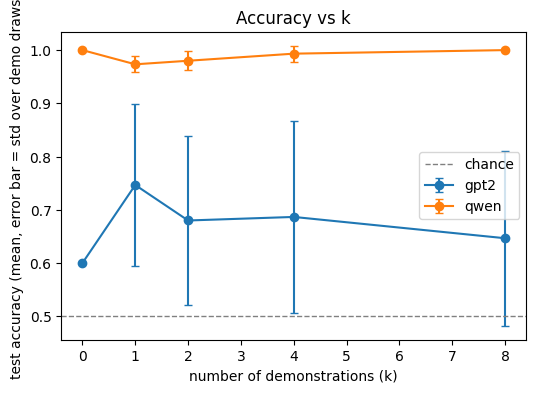

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
for name in models:
    g = df_k[df_k.model == name].groupby("k")["acc"]
    ax.errorbar(g.mean().index, g.mean().values, yerr=g.std().fillna(0).values,
                marker="o", capsize=3, label=name)
ax.axhline(0.5, color="grey", linestyle="--", linewidth=1, label="chance")
ax.set_xlabel("number of demonstrations (k)")
ax.set_ylabel("test accuracy (mean, error bar = std over demo draws)")
ax.set_title("Accuracy vs k")
ax.legend()
plt.show()

**Accuracy vs k (labelled format)**

- GPT-2 does not improve reliably with more demonstrations. Accuracy peaks at k=1 (0.747) and drifts back to 0.647 by k=8, with std around 0.15-0.18 across demo draws, so the error bars overlap chance (0.5) at several points. The pred_pos and label_mass columns suggest why: at k=0 it predicts positive 90% of the time (label_mass ≈ 0.001), and by k=4-8 it flips to mostly predicting negative (pred_pos ≈ 0.16-0.19), so the demos mainly teach the label format (label_mass rises to 0.96) while the model's label bias just changes direction.

- Qwen is near ceiling at every k (0.97-1.00) with tiny variance, and pred_pos stays at about 0.5, so it is unbiased and already solves the task zero-shot. Demonstrations only raise its label_mass (0.26 to 0.99), meaning they help format adherence, not task ability.

## Part 3: Does the order of examples matter?
Hold everything fixed: the same four demonstrations, the same format. Only the order changes. If accuracy moves, the content did not change, only the sequence did, so the effect is entirely positional. We use three different four-demo sets (seeds 0, 1, 2) and eight random orderings of each.

The number to watch is the spread within a set, compared against the gain you saw from adding examples in Part 2.

Hypothesis: order of examples

**Quick context:** a transformer reads the whole context at once, so in principle order is only information about position. In practice, recent examples often get more weight, and the label of the last demonstration is a common nudge.

Before running the next cell, predict the spread (best ordering minus worst) and why.

- GPT-2:
- Qwen:

Will ordering move accuracy more or less than going from k=0 to k=4:

In [ ]:
rows = []
for name in models:
    for set_seed in range(3):
        base = sample_demos(4, set_seed)
        for order_seed in range(8):
            r = evaluate(name, reorder(base, order_seed), "labelled")
            rows.append({"sweep": "order", "model": name, "k": 4, "seed": set_seed,
                         "order_seed": order_seed, "format": "labelled", **r})

df_o = log_run(rows)
(df_o.groupby(["model", "seed"])["acc"]
     .agg(mean="mean", std="std", min="min", max="max")
     .assign(spread=lambda d: d["max"] - d["min"]).round(3))

mean    std    min  max  spread
model seed                                  
gpt2  0     0.692  0.143  0.500  0.9   0.400
      1     0.746  0.115  0.533  0.9   0.367
      2     0.617  0.170  0.500  0.9   0.400
qwen  0     1.000  0.000  1.000  1.0   0.000
      1     1.000  0.000  1.000  1.0   0.000
      2     0.979  0.017  0.967  1.0   0.033

**Demo ordering (k=4, 8 orderings per demo set)**

- For GPT-2, ordering alone swings accuracy a lot: the spread between best and worst ordering is 0.37-0.40 for every demo set (min 0.50, which is chance, up to max 0.90), with std 0.12-0.17. That is far larger than the change from k=0 to k=4 (0.600 to 0.687), so with GPT-2 the order of the same four examples matters more than adding examples.

- Qwen is essentially order-invariant: spread is 0.000 for two demo sets and only 0.033 for set 2 (mean 0.979), so ordering barely moves it.

## Part 4: Does the format of examples matter?
Same task, same demonstrations, three ways of writing them down: a compact `Review: / Sentiment:` pair, a `Q: / A:` layout with the question spelled out, and a plain sentence that ends in the label. We hold k = 4 and use the same five demo draws for every format, so format is the only thing that changes between columns.

Hypothesis: format of examples

**Quick context:** these are base models that continue text. A format that looks like something common in their training data may be easier to continue than one that does not, whether or not the task content is identical.

Before running the next cell, rank the formats from best to worst for each model, and say why.

GPT-2:
Qwen:
Will the ranking be the same for both models:

In [ ]:
rows = []
for name in models:
    for fmt in FORMATS:
        for s in SEEDS:
            r = evaluate(name, sample_demos(4, s), fmt)
            rows.append({"sweep": "format", "model": name, "k": 4, "seed": s, "format": fmt, **r})

df_f = log_run(rows)
(df_f.groupby(["model", "format"])[["acc", "pred_pos", "label_mass"]]
     .agg(["mean", "std"]).round(3))

acc        pred_pos        label_mass       
                 mean    std     mean    std       mean    std
model format                                                  
gpt2  labelled  0.687  0.180    0.187  0.180      0.922  0.022
      qa        0.667  0.160    0.367  0.337      0.964  0.016
      sentence  0.660  0.136    0.240  0.280      0.919  0.022
qwen  labelled  0.993  0.015    0.507  0.015      0.973  0.006
      qa        1.000  0.000    0.500  0.000      0.998  0.000
      sentence  0.987  0.018    0.513  0.018      0.962  0.011

**Demo format (k=4, three formats: labelled, qa, sentence)**

- GPT-2 ranks labelled (0.687) > qa (0.667) > sentence (0.660), but the gaps are about 0.03 while std is 0.14-0.18, so the format ranking is within noise and format does not clearly matter for accuracy. What does change is the bias: pred_pos moves from 0.19 (labelled) to 0.37 (qa) with very high variance, and qa gives the highest label_mass (0.964), so format shifts which label GPT-2 leans toward more than how often it is right.

- Qwen is at ceiling in all three (0.987-1.000, std ≤ 0.018), with qa best (1.000, label_mass 0.998) and sentence slightly lowest (0.987). The ranking is not meaningfully the same or different from GPT-2's, since Qwen's differences are too small to separate.


## Part 5: The context window is a budget
Every demonstration costs tokens, and every model has a hard ceiling. We read the limit from each model's config, measure what our prompts actually use, and then look at two ways this goes wrong in practice.

Hypothesis: context budget

**Quick context:** GPT-2 has 1024 positions. Qwen2.5-0.5B is configured for far more. Our demonstrations are short, so we are nowhere near the limit at k = 8, but real tasks with long documents hit it quickly.

Before running the next cell, predict how many of our demonstrations would fit in GPT-2's window.

Estimate of the maximum k for GPT-2 with the `labelled` format:

In [ ]:
rows = []
for name, tok in tokenizers.items():
    limit = models[name].config.max_position_embeddings
    for fmt in FORMATS:
        for k in [0, 2, 8, 16]:
            n = len(tok(build_prompt(sample_demos(k, 0), TEST[0][0], fmt))["input_ids"])
            rows.append({"model": name, "format": fmt, "k": k, "prompt_tokens": n,
                         "window": limit, "pct_of_window": round(100 * n / limit, 1)})
df_ctx = pd.DataFrame(rows)
print(df_ctx.pivot_table(index=["model", "format"], columns="k", values="prompt_tokens"))

# rough capacity: window divided by tokens per demonstration
for name, tok in tokenizers.items():
    per_demo = (len(tok(build_prompt(sample_demos(16, 0), TEST[0][0], "labelled"))["input_ids"])
                - len(tok(build_prompt([], TEST[0][0], "labelled"))["input_ids"])) / 16
    limit = models[name].config.max_position_embeddings
    print(f"{name}: ~{per_demo:.0f} tokens per demo, roughly {int(limit // per_demo)} demos fit in {limit} positions")

k                 0     2      8      16
model format                            
gpt2  labelled  21.0  63.0  193.0  363.0
      qa        30.0  90.0  274.0  516.0
      sentence  21.0  61.0  185.0  348.0
qwen  labelled  20.0  58.0  177.0  331.0
      qa        29.0  85.0  258.0  484.0
      sentence  21.0  59.0  178.0  333.0
gpt2: ~21 tokens per demo, roughly 47 demos fit in 1024 positions
qwen: ~19 tokens per demo, roughly 1685 demos fit in 32768 positions


### Failing loudly, and truncating the right end
Two engineering habits worth building now. First, check the length before the forward pass and raise a clear error, rather than letting the model fail somewhere deep and unreadable. Second, if you must truncate, know which end the tokenizer cuts. By default it cuts the **right** side, which in a few-shot prompt is exactly where the question lives.

In [ ]:
def assert_fits(name, prompt):
    n = len(tokenizers[name](prompt)["input_ids"])
    limit = models[name].config.max_position_embeddings
    if n > limit:
        raise ValueError(f"{name}: prompt is {n} tokens, window is {limit}")
    return n


long_demos = [POOL[i % len(POOL)] for i in range(80)]
long_prompt = build_prompt(long_demos, TEST[0][0], "labelled")

try:
    assert_fits("gpt2", long_prompt)
except ValueError as e:
    print("Guard caught it:", e)

tok = tokenizers["gpt2"]
limit = models["gpt2"].config.max_position_embeddings
original_side = tok.truncation_side
try:
    for side in ["right", "left"]:
        tok.truncation_side = side
        ids = tok(long_prompt, truncation=True, max_length=limit)["input_ids"]
        print(f"truncation_side={side!r}: {len(ids)} tokens, ends with -> {tok.decode(ids[-14:])!r}")
finally:
    tok.truncation_side = original_side

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1731 > 1024). Running this sequence through the model will result in indexing errors


Guard caught it: gpt2: prompt is 1731 tokens, window is 1024
truncation_side='right': 1024 tokens, ends with -> ', it is flimsy and overpriced.\nSentiment: negative'
truncation_side='left': 1024 tokens, ends with -> ' coffee was excellent and the staff remembered my name.\nSentiment:'


**Context budget (GPT-2 vs Qwen)**

GPT-2 uses roughly 21 tokens per labelled demo, so about 47 demos fit in its 1024-position window, which means k=8 (193 tokens, about 19% of the window) is nowhere near the limit. Qwen's 32768-token window fits about 1685 demos. The qa format is the most expensive (516 tokens at k=16 vs 363 labelled for GPT-2), so format choice changes the budget by roughly 40%, and for long documents GPT-2's window would run out quickly while Qwen's effectively would not.

## Part 6: Sampling, from the logits up
Last week you read a distribution off the final position. Sampling is what happens next: we reshape that distribution and draw from it. Temperature rescales the logits, top-k keeps only the k most likely tokens, and top-p keeps the smallest set of tokens whose probability adds up to p. The functions are defined above and checked. Here we point them at real distributions from the week 1 prompts.

For each setting we report the entropy of the reshaped distribution, how many tokens are still possible, how much probability the original top token now has, and what happens over 500 actual draws.

Hypothesis: sampling settings

**Quick context:** lowering temperature sharpens the distribution without removing any token, while top-k and top-p remove tokens outright. On a prompt where the model is already confident, a filter has little left to remove. On an open-ended prompt, it has a lot.

Before running the next cell, predict which setting changes the factual prompt least, and which changes the ambiguous prompt most.

Factual prompt, least affected setting:
Ambiguous prompt, most affected setting:
Does top-p=0.9 behave the same on both prompts:

In [ ]:
SAMPLING_MODEL = "qwen"
prompts = {
    "factual": "The capital of France is",
    "ambiguous": "My favorite thing about weekends is",
}
settings = {
    "baseline (T=1)":      dict(T=1.0),
    "T=0.3":               dict(T=0.3),
    "T=1.5":               dict(T=1.5),
    "top_k=5":             dict(top_k=5),
    "top_p=0.9":           dict(top_p=0.9),
    "top_p=0.5":           dict(top_p=0.5),
    "T=0.7 + top_p=0.9":   dict(T=0.7, top_p=0.9),
}


@torch.no_grad()
def next_token_logits(name, prompt):
    tok, model = tokenizers[name], models[name]
    inputs = tok(prompt, return_tensors="pt").to(device)
    return model(**inputs).logits[0, -1].float().cpu()


rows = []
for label, prompt in prompts.items():
    logits = next_token_logits(SAMPLING_MODEL, prompt)
    top1 = int(logits.argmax())
    for sname, kw in settings.items():
        probs = filtered_distribution(logits, **kw)
        gen = torch.Generator().manual_seed(0)
        draws = [sample_token(logits, generator=gen, **kw) for _ in range(500)]
        rows.append({
            "prompt": label, "setting": sname,
            "entropy": round(entropy_nats(probs), 3),
            "tokens_alive": int((probs > 0).sum()),
            "p_top1": round(probs[top1].item(), 3),
            "distinct_in_500": len(set(draws)),
            "top1_share_of_draws": round(draws.count(top1) / 500, 3),
        })

df_s = pd.DataFrame(rows)
RUNS.extend({"sweep": "sampling", "model": SAMPLING_MODEL, **r} for r in rows)
df_s

,prompt,setting,entropy,tokens_alive,p_top1,distinct_in_500,top1_share_of_draws
0,factual,baseline (T=1),3.258,151936,0.316,82,0.330
1,factual,T=0.3,0.223,151930,0.956,4,0.972
2,factual,T=1.5,6.622,151936,0.092,275,0.100
3,factual,top_k=5,1.321,5,0.526,5,0.558
4,factual,top_p=0.9,2.558,37,0.351,33,0.368
5,factual,top_p=0.5,1.126,4,0.575,4,0.604
6,factual,T=0.7 + top_p=0.9,1.292,8,0.627,8,0.636
7,ambiguous,baseline (T=1),4.799,151936,0.130,160,0.130
8,ambiguous,T=0.3,1.005,151936,0.627,7,0.604
9,ambiguous,T=1.5,7.906,151936,0.030,366,0.022


**Sampling settings (Qwen, factual vs ambiguous prompt)**

Top_p=0.9 does not behave the same on both prompts: on the factual prompt it keeps 37 tokens and gives 33 distinct outputs in 500 draws, while on the ambiguous prompt it keeps 320 tokens and gives 118 distinct outputs. The factual prompt is least affected by T=0.3 in terms of diversity collapse (4 distinct, p_top1 0.956) only in the sense that it is already near-deterministic, and the ambiguous prompt is most affected by T=1.5 (entropy 7.906, 366 distinct, p_top1 0.030), which makes it close to random sampling. Filters (top_k=5, top_p=0.5) collapse both prompts to a handful of options (4-11 distinct), so the effect of a filter depends on how much probability mass the model spreads beyond the top tokens.

## Save the log


In [ ]:
df_all = pd.DataFrame(RUNS)
df_all.to_csv("week2_results.csv", index=False)
print(f"Saved {len(df_all)} rows to week2_results.csv")
df_all.groupby("sweep").size()

Saved 134 rows to week2_results.csv


,0
sweep,
format,30
k,42
order,48
sampling,14
